# Exercise 2
Today we are going to continue to work on point clouds.
We will work on clustering point clouds. That enables us to segment them.

In [1]:
import numpy as np
import open3d as o3d
import copy
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.cluster import KMeans, k_means

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# Helper to visualize clustering results by coloring each point according to
# its assigned cluster label.
# Why a colormap (tab20) instead of manually picking colors: 'tab20' is a
# built-in matplotlib palette designed to give up to 20 visually distinct colors.
# Sampling from it based on each label lets an arbitrary number of clusters each
# get their own clearly different color, without having to hand-pick a color per
# cluster.
# Why labels / max_label: colormaps in matplotlib expect an input in the [0, 1]
# range, not raw integer cluster indices. Dividing every label by the largest
# label value rescales them into that range so cmap() can convert them to actual
# RGB(A) colors. The 'if max_label > 0 else 1' guard avoids a division-by-zero
# in the edge case where there's only a single cluster (label 0 for everyone).
# Why colors[labels < 0] = 0: some clustering algorithms can mark certain points
# as unassigned/noise using a negative label (-1). Forcing these to black
# (0,0,0,0) visually distinguishes "not confidently assigned to any cluster"
# points from the real clusters.
def draw_labels_on_model(pcl, labels, show_normals=False):
    cmap = plt.get_cmap("tab20")
    pcl_temp = copy.deepcopy(pcl)
    max_label = labels.max()
    print("%s has %d clusters" % (pcl_name, max_label + 1))
    colors = cmap(labels / (max_label if max_label > 0 else 1))
    colors[labels < 0] = 0
    pcl_temp.colors = o3d.utility.Vector3dVector(colors[:, :3])
    o3d.visualization.draw_geometries([pcl_temp], point_show_normal=show_normals)

## K-means on a cube
We created a point cloud using `open3d`.
Our goal is to segment each side using k-means.

In [3]:
# Create a simple test case: a uniformly-sampled cube surface, so we know
# exactly what a "correct" segmentation should look like (6 clusters, one per
# face) before trying k-means on it.
# Why start with a cube specifically: its ground truth is completely
# unambiguous. A correct clustering assigns every point to exactly one of the
# cube's 6 flat faces; making it a simple benchmark for comparing different
# feature choices.
# Why sample_points_uniformly(density): a mesh only defines the cube's surface
# geometry (vertices/faces), not individual data points. Sampling converts it
# into an actual point cloud with ~10,000 points spread evenly across all 6 faces.
pcl_name = "Cube"
# Density of sample points to create.
density = 1e4
pcl = o3d.geometry.TriangleMesh.create_box().sample_points_uniformly(
    int(density)
)
eps = 0.4
print("%s has %d points" % (pcl_name, np.asarray(pcl.points).shape[0]))
o3d.visualization.draw_geometries([pcl])

Cube has 10000 points


If we just use k-means out of the box with the point cloud, we will get what just has been visualized.

Note: Using the '+' and '-' keys in the viewer will increase/decrease the size of the points.

In [4]:
# Run k-means directly on raw (x, y, z) point positions. k-means groups points
# by spatial (Euclidean) proximity in whatever feature space it's given. On a
# cube, points near a shared edge between two different faces are spatially
# close to each other even though they belong to different faces, while two
# points on opposite corners of the same face can be relatively far apart.
# Position alone doesn't encode "which flat surface does this point belong to",
# so k-means ends up dividing the cube into 6 cube-shaped spatial chunks rather
# than into its 6 actual faces.
km = KMeans(
    n_clusters=6,
    init="random",
    n_init=10,
    max_iter=300,
    tol=1e-04,
    random_state=0,
)

# Get the points from the pointcloud as nparray.
xyz = np.asarray(pcl.points)
labels = km.fit_predict(xyz)
draw_labels_on_model(pcl, labels)

Cube has 6 clusters


We can see that we get six clusters, but they do not span a side.

We try again, but this time we instead use the normals of the cube as input for k-means.

The normals for each plane should be parallel with the other normals from said plane.

In [5]:
# Why normals seem promising: every point on the same flat face of a cube should
# have (approximately) the exact same normal direction, since a flat face
# doesn't curve. Clustering by normal direction alone should group all "top face"
# points together, all "front face" points together, etc., regardless of where
# on that face each point sits.
# Why radius=0.1, max_nn=30 for estimate_normals(): these control the local
# neighborhood size used to estimate each point's normal. A radius small enough
# to stay within one face's local neighborhood but large enough to average out
# sampling noise into an accurate normal estimate.
# Why this still doesn't fully work: two opposite/parallel faces of a cube (e.g.
# top and bottom) have normals pointing in exactly opposite directions (n and -n).
# Euclidean distance between these two normal vectors is actually large, so this
# alone doesn't necessarily merge opposite faces together, but it also means
# faces sharing a similar general orientation direction can be ambiguous in a
# way pure position wasn't.
# Estimate normals for every point, then run k-means on the normals alone.
pcl.estimate_normals(
    search_param=o3d.geometry.KDTreeSearchParamHybrid(radius=0.1, max_nn=30)
)

normals = np.asarray(pcl.normals)

km = KMeans(
    n_clusters=6,
    init="random",
    n_init=10,
    max_iter=300,
    tol=1e-04,
    random_state=0,
)
labels = km.fit_predict(normals)
draw_labels_on_model(pcl, labels, show_normals=True)

Cube has 6 clusters


This still does not fully work. Normal estimation has a direction ambiguity: a local plane can be represented by either $\vec{n}$ or $-\vec{n}$, so points belonging to the same face may initially have normals pointing in opposite directions.

In the image below, for example, some of the pink/purple points have normals pointing in opposite directions even though they belong to the same surface. This means that the normal direction can directly affect the clustering result.

We can reduce this problem by consistently orienting neighboring normals using orient_normals_consistent_tangent_plane().

However, this still does not uniquely identify opposite faces. Depending on how the normals are oriented, two different faces may end up with similar normal directions. To make the clustering more robust, we can therefore combine the xyz coordinates with the surface normals.

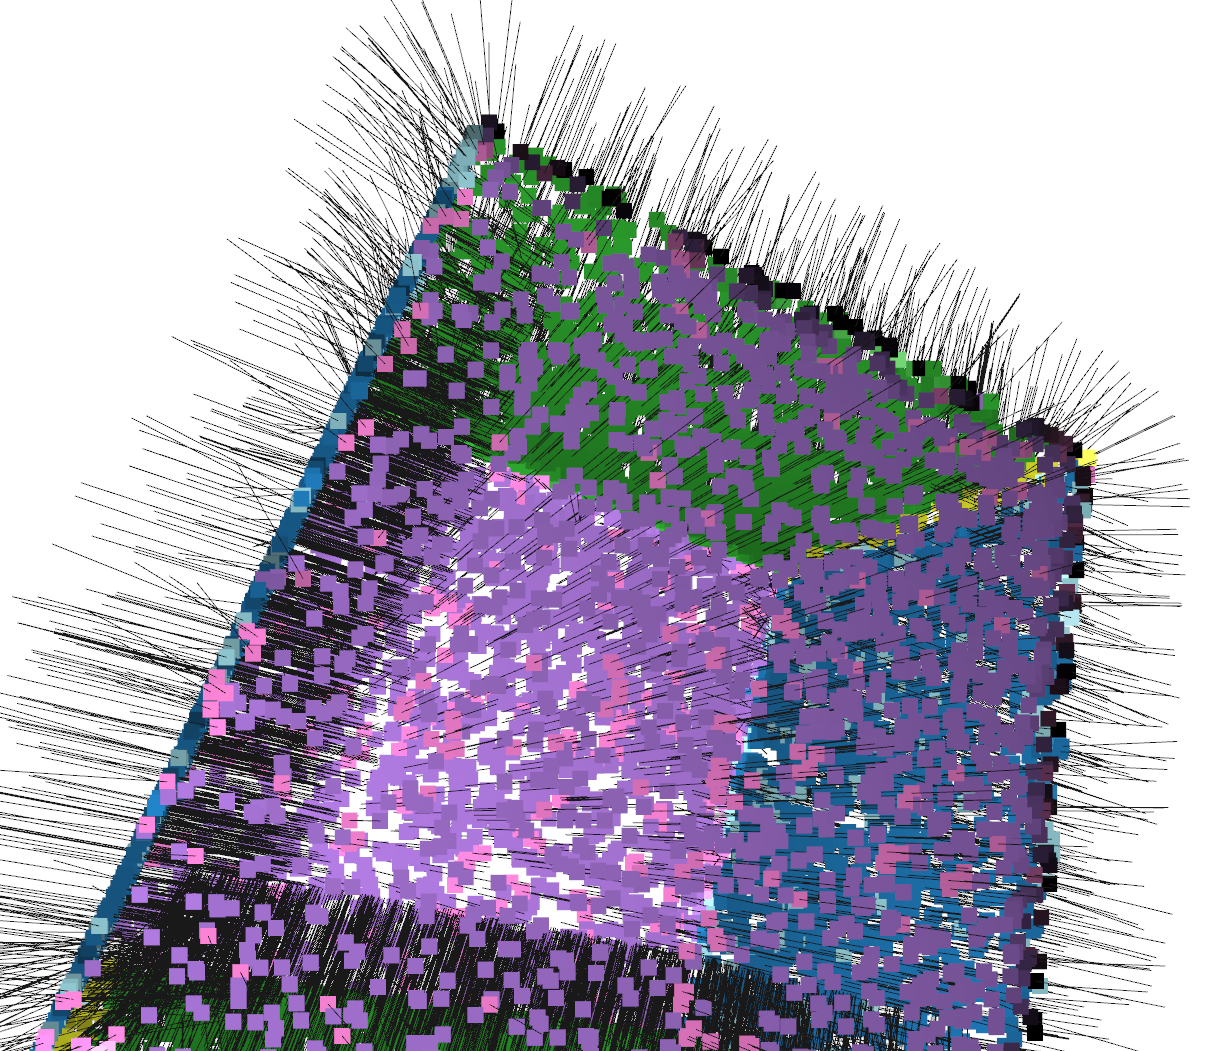

In [8]:
from IPython.display import Image, display
display(Image(filename="normals.png"))

In [9]:
# Make neighboring normals consistently oriented.
# Normal estimation has a sign ambiguity: n and -n describe the same local plane.
# This step propagates a consistent orientation across neighboring points.
pcl.orient_normals_consistent_tangent_plane(k=30)

normals = np.asarray(pcl.normals)

km = KMeans(
    n_clusters=6,
    init="random",
    n_init=10,
    max_iter=300,
    tol=1e-04,
    random_state=0,
)
labels = km.fit_predict(normals)
draw_labels_on_model(pcl, labels, show_normals=True)

Cube has 6 clusters


## More exercises

### A) K-means continued.

Combine the point cloud points (xyz) with the normals and do k-means.

```xyz_n = np.concatenate((xyz, normals), axis=1)```

Do you get better clusters?
Why would adding the normals help?

In [11]:
# Why concatenate xyz and normals: stacking them side by side
# (np.concatenate(..., axis=1)) turns each point into a single 6-dimensional
# vector [x, y, z, nx, ny, nz]. k-means' Euclidean distance in this combined
# space then accounts for both how close two points are in space and how
# similarly their local surfaces are oriented.
xyz = np.asarray(pcl.points)
pcl.estimate_normals(
    search_param=o3d.geometry.KDTreeSearchParamHybrid(radius=0.1, max_nn=30)
)
normals = np.asarray(pcl.normals)

xyz_n = np.concatenate((xyz, normals), axis=1)

km = KMeans(
    n_clusters=6,
    init="random",
    n_init=10,
    max_iter=300,
    tol=1e-04,
    random_state=0,
)
labels = km.fit_predict(xyz_n)
draw_labels_on_model(pcl, labels)

Cube has 6 clusters


Concatenating `xyz` and `normals` gives each point 6 features instead of 3: its position and its local surface orientation.

This helps because position alone groups points that are spatially close, even if they belong to different faces, such as points near a shared edge. Normals alone group points by orientation regardless of where they are located, and they can also be affected by normal-direction ambiguity.

Combining both gives k-means information about both **where a point is** and **which direction its surface is facing**, making it easier to separate the different cube faces.

### B) 
Try weighting either the points or normals by scaling them by some factor. Can this perfectly segment each of the faces of the cube?


In [18]:
# Why weight the normals:
# K-means uses Euclidean distance over all input features, so changing the scale
# of the normals changes how much surface orientation influences the clustering
# compared with xyz position.
# A larger normal weight makes k-means care more about differences in face
# orientation. For this cube, larger weights such as 5 or 10 give visually
# cleaner face boundaries than using xyz and normals with equal importance.

for w in [0.5, 1, 3, 5, 10]:
    xyz_n_weighted = np.concatenate((xyz, w * normals), axis=1)

    km = KMeans(
        n_clusters=6,
        init="random",
        n_init=10,
        max_iter=300,
        tol=1e-04,
        random_state=0,
    )
    labels = km.fit_predict(xyz_n_weighted)
    print(f"weight={w}: cluster sizes = {np.bincount(labels)}")


# Visualize one of the larger normal weights.
w = 5
xyz_n_weighted = np.concatenate((xyz, w * normals), axis=1)

km = KMeans(
    n_clusters=6,
    init="random",
    n_init=10,
    max_iter=300,
    tol=1e-04,
    random_state=0,
)

labels = km.fit_predict(xyz_n_weighted)
draw_labels_on_model(pcl, labels)

weight=0.5: cluster sizes = [1633 1706 1633 1675 1704 1649]
weight=1: cluster sizes = [1652 1675 1631 1702 1706 1634]
weight=3: cluster sizes = [1637 1629 1652 1704 1675 1703]
weight=5: cluster sizes = [1630 1703 1637 1675 1704 1651]
weight=10: cluster sizes = [1630 1703 1637 1675 1704 1651]
Cube has 6 clusters


Increasing the weight of the normals gives surface orientation more influence in the clustering. In this example, larger weights such as 5 or 10 produce cleaner face boundaries than using position and normals with equal importance.

This suggests that the normals are more informative than the xyz coordinates for separating the different cube faces. Increasing the weight beyond this point does not seem to change the result much.

### C)
Try to cluster all the different shapes using k means.
```{Python}
d = 4
mesh = o3d.geometry.TriangleMesh.create_tetrahedron().translate((-d, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_octahedron().translate((0, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_icosahedron().translate((d, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_torus().translate((-d, -d, 0))
mesh += o3d.geometry.TriangleMesh.create_mobius(twists=1).translate(
    (0, -d, 0))
mesh += o3d.geometry.TriangleMesh.create_mobius(twists=2).translate(
    (d, -d, 0))
mesh.sample_points_uniformly(int(1e5)), 0.5
```

In [19]:
# Unlike the cube's faces (which touch each other and share edges), the 6 shapes
# are translated apart from each other by a fixed distance 'd'. Meaning position
# alone should already be a strong strong signal for separating them, without
# needing normals to help disambiguate nearby-but-differently-oriented. The
# rest of the cell repeats the same estimate_normals -> concatenate(xyz, normals)
# -> KMeans(n_clusters=6) pipeline.
d = 4
mesh = o3d.geometry.TriangleMesh.create_tetrahedron().translate((-d, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_octahedron().translate((0, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_icosahedron().translate((d, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_torus().translate((-d, -d, 0))
mesh += o3d.geometry.TriangleMesh.create_mobius(twists=1).translate((0, -d, 0))
mesh += o3d.geometry.TriangleMesh.create_mobius(twists=2).translate((d, -d, 0))

pcl_name = "Combined shapes"
pcl_shapes = mesh.sample_points_uniformly(int(1e5))
xyz = np.asarray(pcl_shapes.points)
pcl_shapes.estimate_normals(
    search_param=o3d.geometry.KDTreeSearchParamHybrid(radius=0.1, max_nn=30)
)
normals = np.asarray(pcl_shapes.normals)
xyz_n = np.concatenate((xyz, normals), axis=1)

km = KMeans(
    n_clusters=6,
    init="random",
    n_init=10,
    max_iter=300,
    tol=1e-04,
    random_state=0,
)
labels = km.fit_predict(xyz_n)
draw_labels_on_model(pcl_shapes, labels)

Combined shapes has 6 clusters


### D)
Now try segmenting a different point cloud located at `pointclouds/fragment.ply`
Are you able to cluster the point cloud?

Which features could be useful to segment this point cloud?
- fpfh features?
- xyz
- normals 
- colors

Are you able to get clusters that make sense? Why?

In [41]:
# Why colors = np.asarray(pcl_frag.colors) might come back empty: unlike the
# synthetic meshes used above, a real scanned point cloud file may or may not
# include per-point color information depending on how it was captured/stored.
# This line extracts whatever color data is present.
# Why compute FPFH features here as a clustering input: FPFH encodes each point's
# local geometric shape context (curvature, surface structure) into a
# 33-dimensional descriptor. The idea being that different surface types might
# cluster together in this richer feature space even when they're not spatially
# adjacent or similarly oriented in the simpler xyz/normal sense.
voxel_size = 0.05
radius_normal = voxel_size * 2
pcl_name = "Fragment"
pcl_frag = o3d.io.read_point_cloud("TestData/fragment.ply")
pcl_frag = pcl_frag.voxleael_down_sample(voxel_size)
print("%s has %d points" % (pcl_name, np.asarray(pcl_frag.points).shape[0]))
o3d.visualization.draw_geometries([pcl_frag])


xyz = np.asarray(pcl_frag.points)
pcl_frag.estimate_normals(
    search_param=o3d.geometry.KDTreeSearchParamHybrid(radius=radius_normal, max_nn=30)
)
pcl_frag.orient_normals_towards_camera_location(
    camera_location=np.array([0.0, 0.0, 0.0])
)
normals = np.asarray(pcl_frag.normals)
colors = np.asarray(pcl_frag.colors)

n_clusters = 8

# xyz only.
km_xyz = KMeans(n_clusters=n_clusters, n_init=10, random_state=0)
labels_xyz = km_xyz.fit_predict(xyz)
draw_labels_on_model(pcl_frag, labels_xyz)

# xyz + normals.
xyz_n = np.concatenate((xyz, normals), axis=1)
km_xyzn = KMeans(n_clusters=n_clusters, n_init=10, random_state=0)
labels_xyzn = km_xyzn.fit_predict(xyz_n)
draw_labels_on_model(pcl_frag, labels_xyzn)

# xyz + normals + colors
xyz_n_c = np.concatenate((xyz, normals, colors), axis=1)
km_xyzn = KMeans(n_clusters=n_clusters, n_init=10, random_state=0)
labels_xyznc = km_xyzn.fit_predict(xyz_n_c)
draw_labels_on_model(pcl_frag, labels_xyznc)

# FPFH features (local geometric signature, 33-D per point).
fpfh = o3d.pipelines.registration.compute_fpfh_feature(
    pcl_frag, o3d.geometry.KDTreeSearchParamHybrid(radius=radius_normal, max_nn=100)
)
fpfh_features = fpfh.data.T

km_fpfh = KMeans(n_clusters=n_clusters, n_init=10, random_state=0)
labels_fpfh = km_fpfh.fit_predict(fpfh_features)
draw_labels_on_model(pcl_frag, labels_fpfh)

Fragment has 1284 points
Fragment has 8 clusters
Fragment has 8 clusters
Fragment has 8 clusters
Fragment has 8 clusters


**Discussion.**
- `xyz` alone clusters by raw spatial proximity; reasonable for splitting large separated objects, but it ignores the actual shape/surface of the scene, so it won't respect object boundaries that are close together in space.
- `normals` add local surface orientation, which helps separate flat regions meeting at an angle, but says nothing about where a point is, so far-apart but similarly-oriented surfaces get merged.
- `colors` are only useful if the scene has visually distinct materials/objects. For a monochrome or uniformly-colored scan they add no information.
- `fpfh` features describe local geometric structure (curvature/shape context) around each point and are the most informative for genuine surface segmentation, but they're 33-dimensional, computed from a neighborhood radius that has to be tuned to the point density, and unlike xyz/normals they don't directly encode position, so points from geometrically similar but spatially distant regions can still be grouped together.

### E)
Use the built-in `cluster_dbscan` algorithm.
Tweak the parameters and see what you get out.

Attempt on the combined figures and on `fragment.ply`
```{Python}
#eps (float) – Density parameter that is used to find neighbouring points.
eps = 0.02

#min_points (int) – Minimum number of points to form a cluster.
min_points = 10

labels = np.array(pcl.cluster_dbscan(eps=eps, min_points=min_points, print_progress=True))
```

In [31]:
# Why DBSCAN is different from k-means here: unlike k-means (which needs the
# number of clusters, n_clusters, specified in advance), DBSCAN instead groups
# together points that are densely packed (within 'eps' distance of enough;
# 'min_points' - other points), and automatically leaves sparse, isolated points
# unlabeled as noise (given the label -1) rather than forcing every point into
# some cluster.
# Why labels.max() + 1 reports the cluster count: DBSCAN's returned labels are
# 0, 1, 2, ... for each discovered cluster, with -1 reserved for noise points.
# Since labels start at 0, the largest label value plus 1 directly gives the
# total number of real (non-noise) clusters found.
# Why very different eps values for the two point clouds: eps needs to roughly
# match the point-to-point spacing/density of whichever point cloud is being
# clustered. The multi-shape scene's points are spread across a much larger
# physical scale than the fragment scan's much finer surface sampling, so each
# needs its own appropriately-scaled eps to correctly distinguish "same cluster"
# from "different cluster" (or noise).
# On the combined shapes point cloud.
eps = 0.4
min_points = 10
labels = np.array(
    pcl_shapes.cluster_dbscan(
        eps=eps, min_points=min_points, print_progress=True
    )
)
print("DBSCAN found %d clusters (plus noise)" % (labels.max() + 1))
draw_labels_on_model(pcl_shapes, labels)

# On the fragment point cloud.
eps = 0.02
min_points = 10
labels_frag = np.array(
    pcl_frag.cluster_dbscan(
        eps=eps, min_points=min_points, print_progress=True
    )
)
print("DBSCAN found %d clusters (plus noise)" % (labels_frag.max() + 1))
draw_labels_on_model(pcl_frag, labels_frag)

# Tips for tuning:
# - eps too small -> Almost everything becomes noise (-1).
# - eps too large -> Everything collapses into one giant cluster
# - min_points controls how strict the "dense enough" requirement is; raise it
#   to ignore sparse groups of points as noise instead of real clusters.

Precompute neighbors.[================>           DBSCAN found 6 clusters (plus noise)
Precompute neighbors.[========Fragment has 6 clusters         ] 75%
Precompute neighbors.[========================================] 100%
Clustering[========================================] 100%
DBSCAN found 10 clusters (plus noise)                         ] 20%
Fragment has 10 clusters
Precompute neighbors.[========================================] 100%
Clustering[=======================================>] 97%